# FEM Errors : Quadrature and machine precision



## One-dimensional FEM problem

Consider

$$
-\frac{d^2u}{dx^2}=-6x,\qquad 0<x<1,
$$

with $u(0)=1$ and $u(1)=2$. The exact solution is

$$
u(x)=1+x^3,\qquad u'(x)=3x^2.
$$

For a linear element $e=[x_1,x_2]$ of length $h=x_2-x_1$,

$$
u^h(x)=N_1(x)u_1+N_2(x)u_2,
\qquad
N_1=\frac{x_2-x}{h},\quad N_2=\frac{x-x_1}{h}.
$$

Its element gradient follows from the FEM $B$-matrix:

$$
\frac{du^h}{dx}=\underbrace{\begin{bmatrix}-1/h & 1/h\end{bmatrix}}_{B}
\begin{Bmatrix}u_1\\u_2\end{Bmatrix}.
$$



In [3]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

np.set_printoptions(precision=8, suppress=True)
print("Machine epsilon (float64) =", np.finfo(np.float64).eps)

Machine epsilon (float64) = 2.220446049250313e-16


## Lagrange basis functions with SymPy



In [4]:
x = sp.symbols('x', real=True)
a, h = sp.symbols('a h', real=True, positive=True)

# Standard Lagrange-product basis in the physical coordinate x
def lagrange_basis(x, nodes, i):
    Ni = sp.Integer(1)
    for j in range(len(nodes)):
        if j != i:
            Ni *= (x - nodes[j]) / (nodes[i] - nodes[j])
    return sp.simplify(Ni)

nodes = [a, a + h]
N = [lagrange_basis(x, nodes, i) for i in range(2)]
B = sp.Matrix([[sp.diff(Ni, x) for Ni in N]])
Ke = sp.simplify(sp.integrate(B.T * B, (x, a, a + h)))

print('N1 =', N[0])
print('N2 =', N[1])
print('B =')
sp.pprint(B)
print('Element stiffness K_e =')
sp.pprint(Ke)

N1 = (a + h - x)/h
N2 = (-a + x)/h
B =
⎡-1   1⎤
⎢───  ─⎥
⎣ h   h⎦
Element stiffness K_e =
⎡ 1   -1 ⎤
⎢ ─   ───⎥
⎢ h    h ⎥
⎢        ⎥
⎢-1    1 ⎥
⎢───   ─ ⎥
⎣ h    h ⎦


## Solve the FEM problem once (an actual assembled system)

For $-u''=f(x)$ with $f(x)=-6x$, the element stiffness matrix and **consistent** load vector are

$$
K^{(e)}=\frac1h\begin{bmatrix}1&-1\\-1&1\end{bmatrix},
\qquad
F^{(e)}=\int_{x_1}^{x_2}\begin{Bmatrix}N_1\\N_2\end{Bmatrix}(-6x)\,dx.
$$



In [5]:
def solve_linear_fem(n_elements):
    x_nodes = np.linspace(0.0, 1.0, n_elements + 1)
    n = len(x_nodes)
    K = np.zeros((n, n))
    F = np.zeros(n)

    for e in range(n_elements):
        xa, xb = x_nodes[e], x_nodes[e + 1]
        he = xb - xa
        Ke = np.array([[1.0, -1.0], [-1.0, 1.0]]) / he
        # Exact consistent nodal load for f(x) = -6*x
        Fe = -he * np.array([2*xa + xb, xa + 2*xb])
        ids = [e, e + 1]
        for i in range(2):
            F[ids[i]] += Fe[i]
            for j in range(2):
                K[ids[i], ids[j]] += Ke[i, j]

    # Eliminate prescribed nodal DOFs: u(0)=1 and u(1)=2
    U = np.zeros(n)
    U[0], U[-1] = 1.0, 2.0
    free = np.arange(1, n - 1)
    U[free] = np.linalg.solve(
        K[np.ix_(free, free)],
        F[free] - K[np.ix_(free, [0, n-1])] @ U[[0, -1]]
    )
    return x_nodes, U, K, F

x_nodes, U, K, F = solve_linear_fem(8)
print('Node     x        FEM u(x)      Exact u(x)')
for i, (xi, ui) in enumerate(zip(x_nodes, U)):
    print(f'{i+1:3d}  {xi:8.5f}  {ui:13.9f}  {1+xi**3:13.9f}')
print('Maximum nodal error =', np.max(np.abs(U - (1+x_nodes**3))))

Node     x        FEM u(x)      Exact u(x)
  1   0.00000    1.000000000    1.000000000
  2   0.12500    1.001953125    1.001953125
  3   0.25000    1.015625000    1.015625000
  4   0.37500    1.052734375    1.052734375
  5   0.50000    1.125000000    1.125000000
  6   0.62500    1.244140625    1.244140625
  7   0.75000    1.421875000    1.421875000
  8   0.87500    1.669921875    1.669921875
  9   1.00000    2.000000000    2.000000000
Maximum nodal error = 2.220446049250313e-16


**Special property of this example:** With constant conductivity/stiffness and exactly integrated element loads, the **linear FEM nodal values are exact in exact arithmetic** for this particular one-dimensional problem. This makes it possible to isolate errors in the *element-gradient calculation* from errors in the global linear solver. Do not interpret this as a general property of FEM.

## Derivative of solution at midpoint

$x_m=0.5$:

$$x_1=x_m-\frac{h}{2},\qquad x_2=x_m+\frac{h}{2}.$$

Insert the exact nodal values $u_1=1+x_1^3$ and $u_2=1+x_2^3$ into the linear FEM element-gradient formula:

$$
\left.\frac{du^h}{dx}\right|_e
=\frac{u_2-u_1}{h}
=3x_m^2+\frac{h^2}{4}.
$$

Since $u'(x_m)=3x_m^2=0.75$,

$$
\boxed{\epsilon_{\mathrm{approx}}=\left|u'_h-u'(x_m)\right|=\frac{h^2}{4}=O(h^2).}
$$

The truncation error decreases with increase in number of elements.

## Subtractive cancellation: where the round-off enters

Stored nodal values have small errors $\widehat u_i=u_i+\delta_i$. Then

$$
\underbrace{\frac{\widehat u_2-\widehat u_1}{h}}_{\mathrm{computed\ FEM\ gradient}}
=\frac{u_2-u_1}{h}+\frac{\delta_2-\delta_1}{h}.
$$

If $|\delta_i|$ is on the scale of machine epsilon $\varepsilon$ times the nodal-value magnitude,

$$
\boxed{\epsilon_{\mathrm{round}}\sim C\frac{\varepsilon_{\mathrm{mach}}}{h}.}
$$

Thus a qualitative combined-error model is

$$
\boxed{\epsilon(h)\sim\frac{h^2}{4}+C\frac{\varepsilon_{\mathrm{mach}}}{h}.}
$$


## FEM error curve



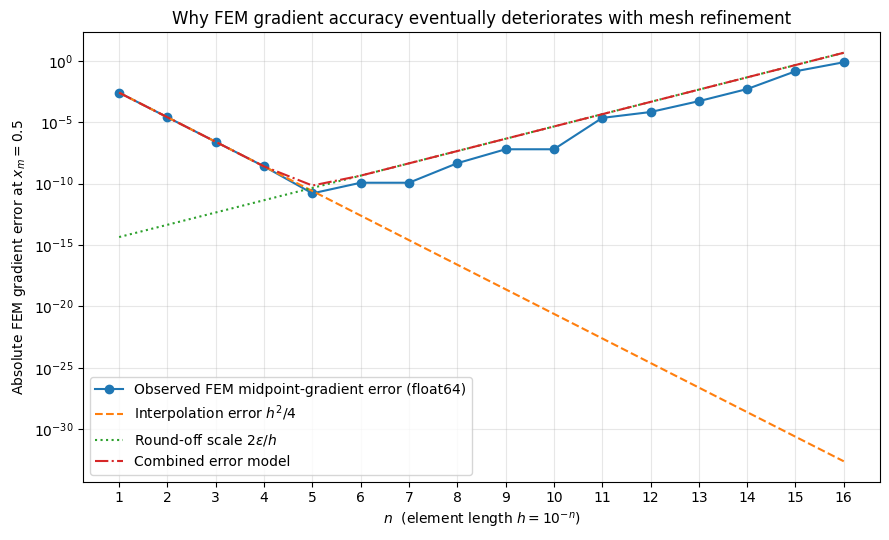

Smallest observed error at h = 1e-05
Minimum observed absolute error = 1.602e-11


In [6]:
xm = 0.5
exact_grad = 3*xm**2
n_values = np.arange(1, 17)
steps = 10.0**(-n_values)
eps = np.finfo(np.float64).eps

errors = []
for he in steps:
    x_left, x_right = xm - he/2.0, xm + he/2.0
    u1 = 1.0 + x_left**3
    u2 = 1.0 + x_right**3
    # FEM gradient: B @ {u1, u2}, evaluated as difference / h
    grad_fem = (u2-u1)/he
    errors.append(abs(grad_fem-exact_grad))

errors = np.array(errors)
truncation = steps**2 / 4.0
roundoff_scale = 2.0 * eps / steps
model = truncation + roundoff_scale

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.semilogy(n_values, errors, 'o-', label='Observed FEM midpoint-gradient error (float64)')
ax.semilogy(n_values, truncation, '--', label=r'Interpolation error $h^2/4$')
ax.semilogy(n_values, roundoff_scale, ':', label=r'Round-off scale $2\varepsilon/h$')
ax.semilogy(n_values, model, '-.', label='Combined error model')
ax.set_xlabel(r'$n$  (element length $h=10^{-n}$)')
ax.set_ylabel(r'Absolute FEM gradient error at $x_m=0.5$')
ax.set_title('Why FEM gradient accuracy eventually deteriorates with mesh refinement')
ax.set_xticks(n_values)
ax.grid(True, which='both', alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

best_idx = int(np.argmin(errors))
print(f'Smallest observed error at h = {steps[best_idx]:.0e}')
print(f'Minimum observed absolute error = {errors[best_idx]:.3e}')

In [7]:
print('   h          FEM gradient       Absolute error     h^2/4')
for he, err, tr in zip(steps, errors, truncation):
    xl, xr = xm-he/2, xm+he/2
    uh_l, uh_r = 1+xl**3, 1+xr**3
    grad = (uh_r-uh_l)/he
    print(f'{he:9.1e}   {grad:17.12f}   {err:13.4e}   {tr:13.4e}')

   h          FEM gradient       Absolute error     h^2/4
  1.0e-01      0.752500000000      2.5000e-03      2.5000e-03
  1.0e-02      0.750025000000      2.5000e-05      2.5000e-05
  1.0e-03      0.750000250000      2.5000e-07      2.5000e-07
  1.0e-04      0.750000002501      2.5007e-09      2.5000e-09
  1.0e-05      0.750000000016      1.6016e-11      2.5000e-11
  1.0e-06      0.749999999883      1.1721e-10      2.5000e-13
  1.0e-07      0.749999999883      1.1721e-10      2.5000e-15
  1.0e-08      0.749999995442      4.5581e-09      2.5000e-17
  1.0e-09      0.750000062055      6.2055e-08      2.5000e-19
  1.0e-10      0.750000062055      6.2055e-08      2.5000e-21
  1.0e-11      0.749977857595      2.2142e-05      2.5000e-23
  1.0e-12      0.750066675437      6.6675e-05      2.5000e-25
  1.0e-13      0.750510764647      5.1076e-04      2.5000e-27
  1.0e-14      0.754951656745      4.9517e-03      2.5000e-29
  1.0e-15      0.888178419700      1.3818e-01      2.5000e-31
  1.0e-16   